# 03 — Exploratory Data Analysis

**Goal:** understand the return/volatility/correlation characteristics of
the asset universe, and check the statistical properties (stationarity,
missing data, sample sufficiency) that determine which downstream modeling
choices are even valid — *before* building features or models. See
`docs/PREPROCESSING_AND_FEATURE_SELECTION.md` §1 for the full rationale
behind each check below.

In [1]:
import sys
from pathlib import Path
PROJECT_ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
plt.rcParams["figure.figsize"] = (10, 5)

np.random.seed(42)

from notebooks.nb_utils import fetch_price_panel

TICKERS = ["AAPL", "MSFT", "GLD", "BND", "SPY"]
START = "2019-01-01"

price_panel, used_synthetic = fetch_price_panel(TICKERS, START)
returns_panel = price_panel.pct_change().dropna()
print(f"Loaded {price_panel.shape[0]} rows x {price_panel.shape[1]} tickers. Synthetic data: {used_synthetic}")
price_panel.tail()

Failed to get ticker 'SPY' reason: Expecting value: line 1 column 1 (char 0)


HTTP Error 403: Host not in allowlist: query2.finance.yahoo.com. Add this host to your network egress settings to allow access.


HTTP Error 403: Host not in allowlist: query1.finance.yahoo.com. Add this host to your network egress settings to allow access.


Failed to get ticker 'MSFT' reason: Expecting value: line 1 column 1 (char 0)


HTTP Error 403: Host not in allowlist: query2.finance.yahoo.com. Add this host to your network egress settings to allow access.


HTTP Error 403: Host not in allowlist: query1.finance.yahoo.com. Add this host to your network egress settings to allow access.


... (7 outputs left out)

['SPY', 'MSFT']: JSONDecodeError('Expecting value: line 1 column 1 (char 0)')


['BND', 'GLD', 'AAPL']: possibly delisted; no timezone found


[info] Live data unavailable (KeyError); using synthetic demo data instead.
Loaded 2004 rows x 5 tickers. Synthetic data: True


,AAPL,MSFT,GLD,BND,SPY
2026-08-31,229.681016,128.274867,119.914845,364.746718,107.728124
2026-09-01,227.093540,128.294744,120.000708,372.445526,106.711406
2026-09-02,229.155329,127.875189,121.085078,365.765614,106.991434
2026-09-03,232.958620,125.652809,122.697759,374.610608,107.656847
2026-09-04,232.705684,125.622649,120.900524,369.667262,106.661264


## Missing data check

Before computing any statistic, confirm how much data is actually missing and whether it's concentrated (e.g. one asset's early history) or scattered (more concerning -- could indicate a data quality issue).

In [2]:
missing = price_panel.isna()
print(f"Total missing cells: {missing.sum().sum()} / {missing.size} ({missing.sum().sum()/missing.size:.2%})")
missing.sum().to_frame("missing_days")

Total missing cells: 0 / 10020 (0.00%)


,missing_days
AAPL,0
MSFT,0
GLD,0
BND,0
SPY,0


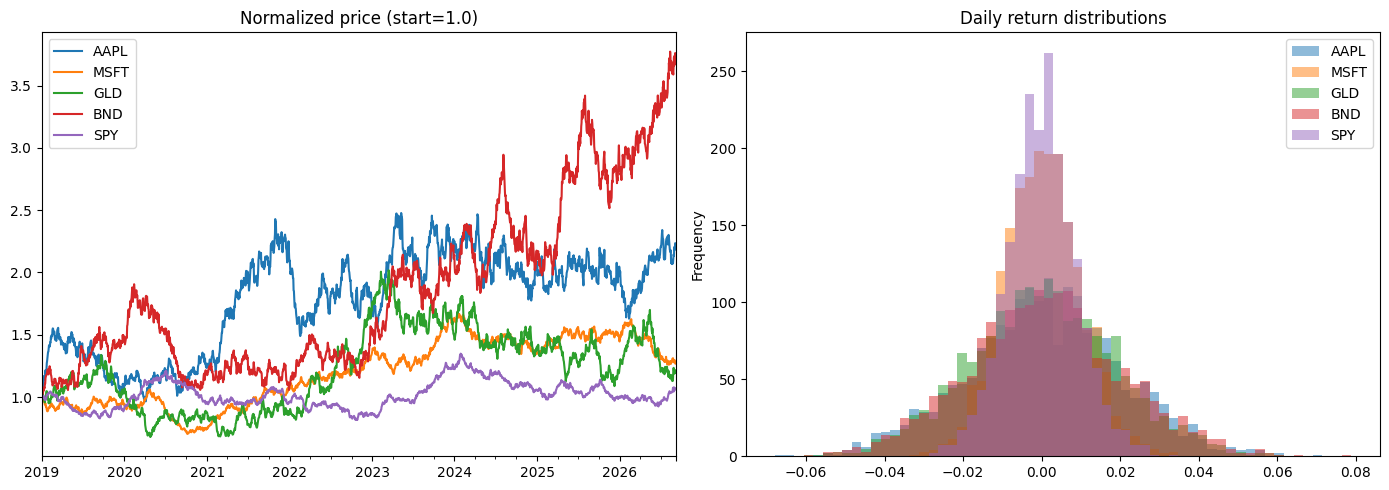

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
(price_panel / price_panel.iloc[0]).plot(ax=axes[0], title="Normalized price (start=1.0)")
returns_panel.plot(kind="hist", bins=60, alpha=0.5, ax=axes[1], title="Daily return distributions")
plt.tight_layout()
plt.show()

In [4]:
stats = pd.DataFrame({
    "ann_return": returns_panel.mean() * 252,
    "ann_volatility": returns_panel.std() * np.sqrt(252),
    "skew": returns_panel.skew(),
    "kurtosis": returns_panel.kurtosis(),
})
stats["sharpe_approx"] = stats["ann_return"] / stats["ann_volatility"]
stats.round(3)

,ann_return,ann_volatility,skew,kurtosis,sharpe_approx
AAPL,0.150,0.313,-0.042,0.050,0.480
MSFT,0.042,0.157,0.081,0.105,0.269
GLD,0.067,0.297,0.024,-0.008,0.225
BND,0.214,0.312,0.093,0.044,0.684
SPY,0.017,0.138,0.064,0.302,0.123


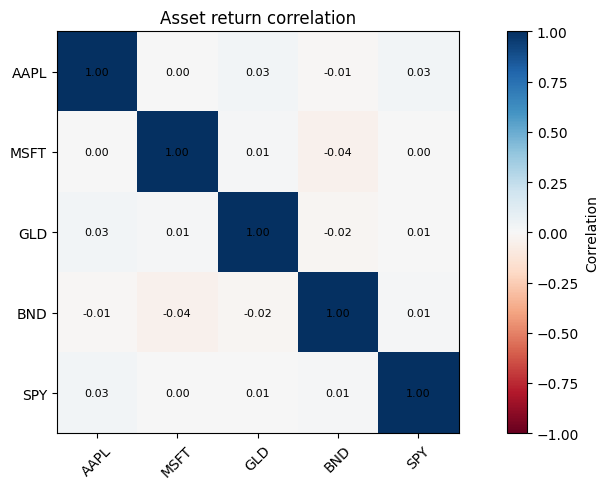

In [5]:
corr = returns_panel.corr()
plt.imshow(corr, cmap="RdBu", vmin=-1, vmax=1)
plt.xticks(range(len(corr)), corr.columns, rotation=45)
plt.yticks(range(len(corr)), corr.columns)
plt.colorbar(label="Correlation")
plt.title("Asset return correlation")
for i in range(len(corr)):
    for j in range(len(corr)):
        plt.text(j, i, f"{corr.iloc[i,j]:.2f}", ha="center", va="center", fontsize=8)
plt.tight_layout()
plt.show()

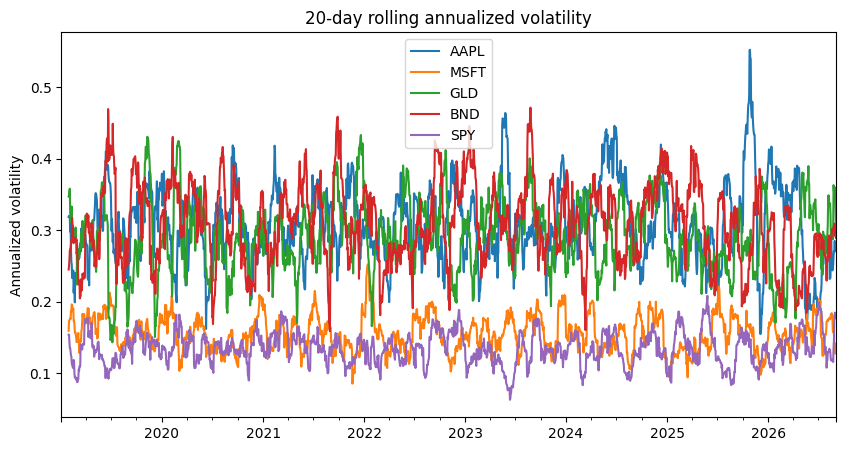

In [6]:
rolling_vol = returns_panel.rolling(20).std() * np.sqrt(252)
rolling_vol.plot(title="20-day rolling annualized volatility")
plt.ylabel("Annualized volatility")
plt.show()

## Stationarity check (Augmented Dickey-Fuller test)

Most statistical/ML modeling assumptions (constant mean/variance) require stationarity. Price **levels** are expected to behave like a random walk (non-stationary, unit root present); **returns** are expected to be stationary. This is the formal justification for why every feature and target in this project is built from returns, not raw price levels — see `docs/PREPROCESSING_AND_FEATURE_SELECTION.md` §1.

In [7]:
from statsmodels.tsa.stattools import adfuller

def adf_summary(series, label):
    result = adfuller(series.dropna())
    return {"series": label, "adf_statistic": result[0], "p_value": result[1], "stationary_at_5pct": result[1] < 0.05}

rows = []
for ticker in TICKERS:
    rows.append(adf_summary(price_panel[ticker], f"{ticker} (price level)"))
    rows.append(adf_summary(returns_panel[ticker], f"{ticker} (daily return)"))

adf_table = pd.DataFrame(rows)
adf_table

,series,adf_statistic,p_value,stationary_at_5pct
0,AAPL (price level),-2.075941,0.254298,False
1,AAPL (daily return),-22.983679,0.000000,True
2,MSFT (price level),-1.163557,0.689073,False
3,MSFT (daily return),-45.688634,0.000000,True
4,GLD (price level),-1.906762,0.328887,False
5,GLD (daily return),-23.986656,0.000000,True
6,BND (price level),0.063819,0.963502,False
7,BND (daily return),-33.019398,0.000000,True
8,SPY (price level),-1.879894,0.341578,False
9,SPY (daily return),-43.939999,0.000000,True


**Expected pattern:** price levels mostly fail to reject the unit-root null (non-stationary, `stationary_at_5pct=False`), while returns reject it comfortably (`stationary_at_5pct=True`). If a real dataset shows otherwise for returns, that's a signal to investigate before trusting downstream volatility/risk calculations that assume roughly stable statistical properties.

## Data sufficiency check

Before any feature or model is built, confirm there's enough history to survive: (1) the longest rolling feature window (252 days for `rolling_drawdown`), (2) the ML target's forward horizon, and (3) the purge/embargo overhead at each split boundary. See `docs/PREPROCESSING_AND_FEATURE_SELECTION.md` §4 for the full accounting.

In [8]:
from src.config import CONFIG

total_days = len(price_panel)
feature_warmup = 252  # longest rolling window (rolling_drawdown)
target_horizon = CONFIG["ml"]["target_horizon_days"]
purge = CONFIG["ml"]["purge_days"]
embargo = CONFIG["ml"]["embargo_days"]

usable_after_warmup = total_days - feature_warmup
usable_after_target = usable_after_warmup - target_horizon
overhead_per_boundary = purge + embargo
usable_after_splits = usable_after_target - 2 * overhead_per_boundary  # two split boundaries

print(f"Total trading days available:        {total_days}")
print(f"Minimum required (config):           {CONFIG['data']['min_history_days']}")
print(f"After 252-day feature warm-up:        {usable_after_warmup}")
print(f"After {target_horizon}-day target horizon:        {usable_after_target}")
print(f"After purge/embargo at both splits:   {usable_after_splits}")
print()
if usable_after_splits < 250:
    print("WARNING: fewer than ~1 year of usable rows remain after all overhead -- "
          "train/validation/test splits will be small. Consider a longer start date.")
else:
    print("Sufficient history remains for a meaningful chronological split.")

Total trading days available:        2004
Minimum required (config):           252
After 252-day feature warm-up:        1752
After 5-day target horizon:        1747
After purge/embargo at both splits:   1733

Sufficient history remains for a meaningful chronological split.


## Takeaways

- Positive kurtosis across assets confirms fat tails vs. a Normal distribution — this is exactly why parametric (Gaussian) VaR tends to understate tail risk relative to historical/Monte Carlo VaR (see notebook 06).
- Volatility clusters visibly over time rather than staying constant — motivates rolling/trailing volatility features (notebook 04) over a single full-sample number.
- The ADF test confirms returns (not price levels) are the correct modeling target for stationarity reasons.
- The data sufficiency check makes explicit how much history is actually usable after feature warm-up, target horizon, and split overhead — a number that's easy to overestimate by just looking at total rows.
- Continue to **04 — Feature Engineering**.